# Two-level-atom non-LTE atmosphere

A scattering atmosphere with thermalisation parameter $\epsilon$ (Jiang 2021, ApJS 253, 49,
sec. 4.5; `decks/nlte_eps1e-1.athinput`, `decks/nlte_eps1e-4.athinput`). The mean intensity $J$
(= $E$ of the M1 run, the grid is $\tau = 10^{-3}(e^{10-x}-1)$) is compared with the exact
transport solution of the same atmosphere (`ref/nlte_exact_eps*.txt`). Error = L1 over
$10^{-3} < \tau < 10^5$. Criterion: within 5 % of the reference L1 (an M1 closure is not exact
transport: the reference values are 1e-4 and 1.3e-3).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/vet_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_vettest/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('VET_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('VET_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10})
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_vettest/src/athena 
runs   runs


In [2]:
TESTS = {'nlte_eps1e-1': '1e-1', 'nlte_eps1e-4': '1e-4'}
res = {t: nb.suite(t, EXE, WORK, THREADS) for t in TESTS}

loading the existing run runs/nlte_eps1e-1
loading the existing run runs/nlte_eps1e-4


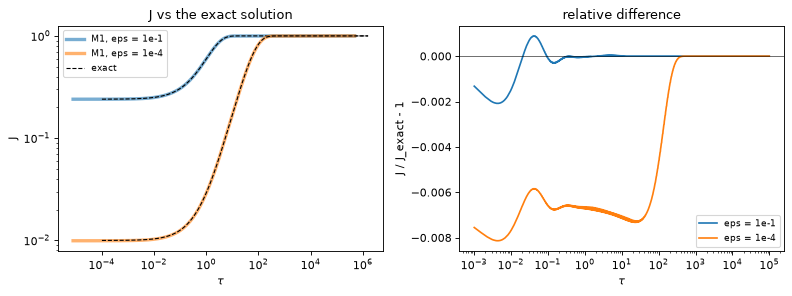

nlte_eps1e-1 L1 = 9.58e-05
PASS nlte_eps1e-1   criterion {"near": {"L1": [9.58e-05, 0.05]}}
nlte_eps1e-4 L1 = 0.00133
PASS nlte_eps1e-4   criterion {"near": {"L1": [0.00133, 0.05]}}


In [3]:
vett = nb.vett
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for t, eps in TESTS.items():
    d = os.path.join(WORK, t, 'run')
    x1 = vett.cell_centres(d)[0]
    J = vett.last_bin(d, 'vet')['vet_e'].mean(axis=(0, 1))
    tau = 1e-3*(np.exp(10.0 - x1) - 1.0)
    te, Je = np.loadtxt(os.path.join(nb.SUITE, 'ref', 'nlte_exact_eps%s.txt' % eps)).T
    axs[0].loglog(tau, J, '-', lw=3, alpha=0.6, label='M1, eps = ' + eps)
    axs[0].loglog(te, Je, 'k--', lw=1, label='exact' if eps == '1e-4' else None)
    s = (tau > 1e-3) & (tau < 1e5)
    ex = np.interp(np.log(tau[s]), np.log(te), Je)
    axs[1].semilogx(tau[s], J[s]/ex - 1, '-', label='eps = ' + eps)
axs[0].set(xlabel=r'$\tau$', ylabel='J', title='J vs the exact solution'); axs[0].legend(fontsize=8)
axs[1].axhline(0, c='k', lw=0.5)
axs[1].set(xlabel=r'$\tau$', ylabel='J / J_exact - 1', title='relative difference'); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
for t in TESTS:
    print(t, 'L1 = %.3g' % res[t]['L1']); nb.verdict(t, res[t])